In [2]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

from utils import get_color_limits
from PIL import Image

In [25]:
coner_track_parameters = {
    "maxCorners" : 10,
    "qualityLevel": 0.3,
    "minDistance": 7,
    "blockSize": 7,
}

lk_parameters = {
    "winSize": (200,200),
    "maxLevel": 3,
    "criteria": (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.05),
}

In [26]:
def detect_blue_object(img, threshold=250):
    image = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # maps
    maps = image.copy()
    blue_map = maps[:,:,-1]
    red_map = maps[:, :, 0]
    green_map = maps[:, :, 1]

    blue_mask = (blue_map >= 245) & (red_map <= 200) & (green_map <= 200)
    mask_white_and_black = Image.fromarray(blue_mask)
    bbox = mask_white_and_black.getbbox()

    if (bbox is not None) and (blue_mask.sum() > 300):
        x1, y1, x2, y2 = bbox
        object_detected = cv2.rectangle(
            image,
            pt1=(x1, y1),
            pt2=(x2, y2),
            color=(0,255,0),
            thickness=5)


        cx = int((x1 + x2) / 2)
        cy = int((y1 + y2) / 2)

        object_detected = cv2.circle(object_detected, (cx, cy), 7, (0, 0, 255), -1)
        points = np.array([cx, cy])
        print(blue_mask.sum())
        print(cx, cy)
        print()


    else:
        points = np.array([])
        object_detected = image

    return cv2.cvtColor(object_detected, cv2.COLOR_RGB2BGR), points

In [58]:
import time
cam = cv2.VideoCapture(0)


while True:
    check, prev_frame = cam.read()
    prev_image = cv2.cvtColor(prev_frame, cv2.COLOR_BGR2GRAY)
    mask = np.zeros_like(prev_frame)
    new_frame, points_to_track  = detect_blue_object(prev_frame)

    cv2.imshow('video', new_frame)

    if points_to_track.any():
        break

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

points_to_track = points_to_track.reshape(-1, 1, 2).astype(np.float32)

while True:
    check, frame = cam.read()
    image = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    next_points, status, err = cv2.calcOpticalFlowPyrLK(prev_image, image, points_to_track, None, **lk_parameters)



    good_new = next_points[status == 1]
    good_prev = points_to_track[status == 1]


    for i, (new, prev) in enumerate(zip(good_new, good_prev)):
        x_new, y_new = new.ravel()
        x_prev, y_prev = prev.ravel()

        mask = cv2.line(mask, (int(x_new), int(y_new)), (int(x_prev), int(y_prev)), (0, 0, 255), 2)
        frame = cv2.circle(frame, (int(x_prev), int(y_prev)), 8, (0, 0, 255), -1)

    prev_image = image
    points_to_track = good_new.reshape(-1, 1, 2).astype(np.float32)

    img = cv2.add(frame, mask)
    cv2.imshow('video', img)


    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cam.release()
cv2.destroyAllWindows()

8684
472 264



TypeError: 'NoneType' object is not subscriptable

In [57]:
qgood_prev

NameError: name 'qgood_prev' is not defined

In [47]:
good_new

array([[516, 327]], dtype=uint64)

In [48]:
mask = cv2.line(mask, (x_new, y_new), (x_prev, y_prev), (0, 0, 255), 2)

In [49]:
frame = cv2.circle(frame, (y_prev, x_prev), 8, (0, 0, 255), -1)

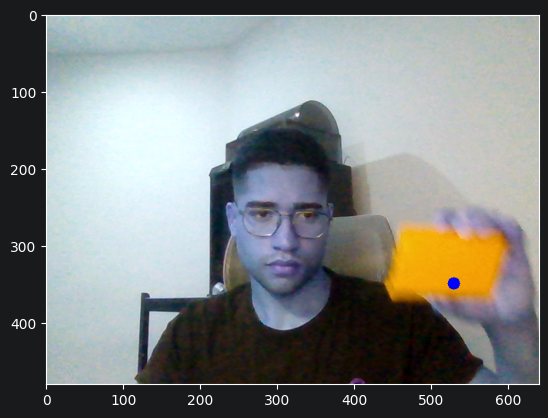

In [50]:
plt.imshow(frame)

In [ ]:
mask.shapeb

In [ ]:
[n.ravel() for n, p in zip(good_new, good_prev)]

In [ ]:
good_prev

In [ ]:
good_new

In [ ]:
image

In [ ]:
points_to_track

In [ ]:
plt.imshow(new_frame)

In [ ]:
marked_image, mask = detect_blue_object(frame)

In [ ]:
mask_contornos = np.where(mask == True, np.uint8(255), np.uint8(0))

# 3. Obtener los contornos pasándole la máscara ya corregida
contornos, jerarquia = cv2.findContours(mask_contornos, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

In [ ]:
jerarquia.shape

In [ ]:
contornos[4].reshape(-1, 2)

In [ ]:
contorno_max = max(contornos, key=cv2.contourArea)

In [ ]:
contorno_max.reshape(-1, 2)

In [ ]:
contorno_max.shape

In [ ]:
M = cv2.moments(contorno_max)

In [ ]:
M

In [ ]:
if M["m00"] != 0:
    cx = int(M["m10"] / M["m00"])
    cy = int(M["m01"] / M["m00"])

    print(f"Centroide detectado en: X={cx}, Y={cy}")

    # Dibujar un punto rojo en el centroide sobre la imagen
    cv2.circle(frame, (cx, cy), 7, (0, 0, 255), -1)
    cv2.putText(frame, "Centro", (cx - 20, cy - 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

In [ ]:
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

In [ ]:
test_mask = Image.fromarray(mask)
bbox_test = test_mask.getbbox()

In [ ]:
plt.imshow(mask)

In [ ]:
cuadro = np.array([[x1, y1], [x2, y2]])

In [ ]:
M = cv2.moments(cuadro.reshape(-1, 1, 2))

In [ ]:
M

In [ ]:
x1, y1, x2, y2 = bbox_test
cx = int((x1 + x2) / 2)
cy = int((y1 + y2) / 2)

In [ ]:
cv2.circle(frame, (cx, cy), 7, (0, 0, 255), -1)
cv2.putText(frame, "Centro Cuadro", (cx - 20, cy - 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

In [ ]:
points_to_track

In [ ]:
frame_bw = cv2.cvtColor(prev_frame, cv2.COLOR_BGR2GRAY)

points = cv2.goodFeaturesToTrack(frame_bw, mask=None, **coner_track_parameters)

In [ ]:
points.shape

In [ ]:
plt.imshow(frame)